<a href="https://colab.research.google.com/github/snehaupadhyay-tech/google_adk/blob/main/PySpark_Data_Insights_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PySpark Data Insights Agent (Google ADK + Colab)

This notebook follows the Session 7 Colab pattern: install dependencies, create a Spark session, load a larger CSV/Parquet dataset, expose a safe PySpark aggregation as an ADK function tool, and ask analytics questions in natural language.

**Deliverables covered**
- Natural-language analytics question
- Tool-based translation into a parameterized PySpark aggregation
- CSV and Parquet support
- Narrated summary returned by the agent
- Bar, line, or pie chart generated from the aggregated result
- Validation and allow-list guardrails
- Optional cross-session memory guidance
- Sample Q&A transcript

## 1. Install packages
Run this once after connecting the Colab runtime. Restart the runtime only if Colab requests it.

In [ ]:
!pip -q install "google-adk>=2.7.0" "pyspark>=3.5,<4.1" pyarrow pandas matplotlib

## 2. Imports and API key
Store the Gemini key in Colab **Secrets** as `GOOGLE_API_KEY`. Do not paste the key into the notebook.

In [26]:
import os, json, re, uuid
from pathlib import Path
from typing import Any, Literal

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import NumericType

from google.colab import userdata, files
from google.adk.agents import Agent
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai import types

os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
assert os.environ.get("GOOGLE_API_KEY"), "Add GOOGLE_API_KEY in Colab Secrets first."

MODEL = "gemini-3.8-flash"
APP_NAME = "pyspark_data_insights"
USER_ID = "sneha"
print("Imports complete.")

Imports complete.


## 3. Start Spark

In [ ]:
from google.colab import userdata
userdata.get('GOOGLE_API_KEY')

In [6]:
spark = (
    SparkSession.builder
    .appName("PySparkDataInsightsAgent")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)

Spark version: 4.0.4


## 4. Create a larger sample dataset
This keeps the notebook runnable even when no external file is supplied. Replace it with your own CSV or Parquet in the next section.

In [7]:
import numpy as np

rng = np.random.default_rng(42)
n = 250_000
pdf = pd.DataFrame({
    "order_id": np.arange(1, n + 1),
    "year": rng.choice([2024, 2025, 2026], n, p=[0.25, 0.40, 0.35]),
    "month": rng.choice(np.arange(1, 13), n),
    "region": rng.choice(["North", "South", "East", "West"], n),
    "category": rng.choice(["Electronics", "Home", "Beauty", "Sports", "Grocery"], n,
                           p=[0.22, 0.20, 0.18, 0.17, 0.23]),
    "channel": rng.choice(["Web", "App", "Store"], n, p=[0.42, 0.33, 0.25]),
    "units": rng.integers(1, 8, n),
    "unit_price": np.round(rng.lognormal(mean=3.45, sigma=0.7, size=n), 2),
    "discount": np.round(rng.uniform(0, 0.35, n), 3),
})
pdf["revenue"] = np.round(pdf["units"] * pdf["unit_price"] * (1 - pdf["discount"]), 2)
pdf["cost"] = np.round(pdf["revenue"] * rng.uniform(0.48, 0.82, n), 2)
pdf["profit"] = np.round(pdf["revenue"] - pdf["cost"], 2)

sample_path = "/content/retail_sales_large.parquet"
pdf.to_parquet(sample_path, index=False)
del pdf
print("Created:", sample_path)

Created: /content/retail_sales_large.parquet


## 5. Load CSV or Parquet
Use the generated Parquet by default. To use your own file, set `UPLOAD_YOUR_FILE=True`.

In [8]:
UPLOAD_YOUR_FILE = False

if UPLOAD_YOUR_FILE:
    uploaded = files.upload()
    DATA_PATH = "/content/" + next(iter(uploaded))
else:
    DATA_PATH = sample_path

suffix = Path(DATA_PATH).suffix.lower()
if suffix == ".csv":
    df = spark.read.option("header", True).option("inferSchema", True).csv(DATA_PATH)
elif suffix in {".parquet", ".pq"}:
    df = spark.read.parquet(DATA_PATH)
else:
    raise ValueError("Only CSV and Parquet files are supported.")

df.cache()
ROW_COUNT = df.count()
print(f"Loaded {ROW_COUNT:,} rows from {DATA_PATH}")
df.printSchema()
df.show(5, truncate=False)

Loaded 250,000 rows from /content/retail_sales_large.parquet
root
 |-- order_id: long (nullable = true)
 |-- year: long (nullable = true)
 |-- month: long (nullable = true)
 |-- region: string (nullable = true)
 |-- category: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- units: long (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- discount: double (nullable = true)
 |-- revenue: double (nullable = true)
 |-- cost: double (nullable = true)
 |-- profit: double (nullable = true)

+--------+----+-----+------+-----------+-------+-----+----------+--------+-------+------+------+
|order_id|year|month|region|category   |channel|units|unit_price|discount|revenue|cost  |profit|
+--------+----+-----+------+-----------+-------+-----+----------+--------+-------+------+------+
|1       |2026|7    |East  |Home       |Web    |4    |34.09     |0.112   |121.09 |89.47 |31.62 |
|2       |2025|1    |North |Electronics|Web    |5    |25.35     |0.118   |111.79 |88.34 |23

## 6. Dataset metadata and safe parameter rules
The model never writes or executes arbitrary PySpark code. It calls one function tool with validated parameters. The tool only allows existing columns, approved aggregation names, equality/list/range filters, safe ordering, and a maximum result size.

In [9]:
SCHEMA = {field.name: field.dataType.simpleString() for field in df.schema.fields}
NUMERIC_COLUMNS = [field.name for field in df.schema.fields if isinstance(field.dataType, NumericType)]
ALL_COLUMNS = list(SCHEMA)

ALLOWED_AGGREGATIONS = {"sum", "avg", "min", "max", "count", "count_distinct"}
ALLOWED_CHARTS = {"bar", "line", "pie", "none"}
LAST_CHART_PATH = None
LAST_TOOL_RESULT = None

print("Columns:", SCHEMA)
print("Numeric columns:", NUMERIC_COLUMNS)

Columns: {'order_id': 'bigint', 'year': 'bigint', 'month': 'bigint', 'region': 'string', 'category': 'string', 'channel': 'string', 'units': 'bigint', 'unit_price': 'double', 'discount': 'double', 'revenue': 'double', 'cost': 'double', 'profit': 'double'}
Numeric columns: ['order_id', 'year', 'month', 'units', 'unit_price', 'discount', 'revenue', 'cost', 'profit']


## 7. PySpark aggregation tool
Supported filters:
- Scalar: `{"year": 2025}`
- List membership: `{"region": ["North", "West"]}`
- Range: `{"revenue": {"min": 100, "max": 500}}`

In [10]:
def run_pyspark_aggregation(
    dimensions: list[str],
    metric: str,
    aggregation: Literal["sum", "avg", "min", "max", "count", "count_distinct"],
    filters: dict[str, Any] | None = None,
    top_n: int = 10,
    sort_order: Literal["asc", "desc"] = "desc",
    chart_type: Literal["bar", "line", "pie", "none"] = "bar",
) -> dict[str, Any]:
    """Run a validated PySpark aggregation and create a chart.

    Args:
        dimensions: Existing categorical/date columns used in groupBy. Use [] for one overall metric.
        metric: Existing column to aggregate. For count, use any existing column.
        aggregation: One of sum, avg, min, max, count, count_distinct.
        filters: Optional mapping of column to scalar, list, or {min, max} range.
        top_n: Number of result rows, from 1 to 50.
        sort_order: asc or desc by the aggregated value.
        chart_type: bar, line, pie, or none.
    """
    global LAST_CHART_PATH, LAST_TOOL_RESULT

    filters = filters or {}
    top_n = max(1, min(int(top_n), 50))

    unknown = [c for c in dimensions + [metric] + list(filters) if c not in ALL_COLUMNS]
    if unknown:
        return {"status": "error", "message": f"Unknown columns: {unknown}", "available_columns": ALL_COLUMNS}
    if aggregation not in ALLOWED_AGGREGATIONS:
        return {"status": "error", "message": f"Unsupported aggregation: {aggregation}"}
    if chart_type not in ALLOWED_CHARTS:
        return {"status": "error", "message": f"Unsupported chart type: {chart_type}"}
    if aggregation in {"sum", "avg", "min", "max"} and metric not in NUMERIC_COLUMNS:
        return {"status": "error", "message": f"{aggregation} requires a numeric metric.", "numeric_columns": NUMERIC_COLUMNS}

    working = df
    for column, value in filters.items():
        if isinstance(value, list):
            working = working.filter(F.col(column).isin(value))
        elif isinstance(value, dict):
            if value.get("min") is not None:
                working = working.filter(F.col(column) >= F.lit(value["min"]))
            if value.get("max") is not None:
                working = working.filter(F.col(column) <= F.lit(value["max"]))
        else:
            working = working.filter(F.col(column) == F.lit(value))

    alias = f"{aggregation}_{metric}"
    if aggregation == "sum": expr = F.sum(metric).alias(alias)
    elif aggregation == "avg": expr = F.avg(metric).alias(alias)
    elif aggregation == "min": expr = F.min(metric).alias(alias)
    elif aggregation == "max": expr = F.max(metric).alias(alias)
    elif aggregation == "count": expr = F.count(metric).alias(alias)
    else: expr = F.countDistinct(metric).alias(alias)

    result = working.groupBy(*dimensions).agg(expr) if dimensions else working.agg(expr)
    result = result.orderBy(F.col(alias).asc() if sort_order == "asc" else F.col(alias).desc()).limit(top_n)
    result_pdf = result.toPandas()

    chart_path = None
    if chart_type != "none" and dimensions and not result_pdf.empty:
        label_col = dimensions[0]
        plot_df = result_pdf.copy()
        if len(dimensions) > 1:
            plot_df["label"] = plot_df[dimensions].astype(str).agg(" | ".join, axis=1)
            label_col = "label"
        fig, ax = plt.subplots(figsize=(9, 5))
        if chart_type == "bar":
            ax.bar(plot_df[label_col].astype(str), plot_df[alias])
            ax.tick_params(axis="x", rotation=35)
        elif chart_type == "line":
            ax.plot(plot_df[label_col].astype(str), plot_df[alias], marker="o")
            ax.tick_params(axis="x", rotation=35)
        elif chart_type == "pie":
            ax.pie(plot_df[alias], labels=plot_df[label_col].astype(str), autopct="%1.1f%%")
        ax.set_title(f"{aggregation.upper()} of {metric} by {' + '.join(dimensions)}")
        if chart_type != "pie":
            ax.set_xlabel(" + ".join(dimensions))
            ax.set_ylabel(alias)
        plt.tight_layout()
        chart_path = f"/content/chart_{uuid.uuid4().hex[:8]}.png"
        plt.savefig(chart_path, dpi=140, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    rows = json.loads(result_pdf.to_json(orient="records"))
    LAST_CHART_PATH = chart_path
    LAST_TOOL_RESULT = rows
    return {
        "status": "success",
        "row_count_in_dataset": ROW_COUNT,
        "plan": {"dimensions": dimensions, "metric": metric, "aggregation": aggregation,
                 "filters": filters, "top_n": top_n, "sort_order": sort_order, "chart_type": chart_type},
        "rows": rows,
        "chart_path": chart_path,
    }

## 8. Define the ADK agent

In [28]:
agent_instruction = f"""
You are a PySpark Data Insights Agent.
The active dataset has {ROW_COUNT:,} rows and this schema: {json.dumps(SCHEMA)}.

For every analytics question:
1. Translate the request into parameters for run_pyspark_aggregation.
2. Call the tool exactly once unless its validation error requires one corrected retry.
3. Never invent columns, values, calculations, or results.
4. Never generate or execute arbitrary Python, SQL, or PySpark code.
5. After a successful tool response, narrate the main result in 2-4 concise sentences.
6. Mention the applied grouping, aggregation, and filters.
7. Tell the user that the chart is displayed below when chart_path is present.
8. If the question cannot be represented by the tool, explain the supported alternatives.
"""

root_agent = Agent(
    name="pyspark_data_insights_agent",
    model=MODEL,
    description="Answers natural-language analytics questions using validated PySpark aggregations.",
    instruction=agent_instruction,
    tools=[run_pyspark_aggregation],
)

session_service = InMemorySessionService()
runner = Runner(agent=root_agent, app_name=APP_NAME, session_service=session_service)
print("Agent ready.")

Agent ready.


## 9. Ask questions
`session_id` keeps context within the current Colab runtime. Use a new ID to simulate a new session.

In [22]:
async def ask_agent(question: str, session_id: str = "session_001") -> str:
    try:
        await session_service.create_session(app_name=APP_NAME, user_id=USER_ID, session_id=session_id)
    except Exception:
        pass

    message = types.Content(role="user", parts=[types.Part(text=question)])
    final_text = ""
    async for event in runner.run_async(user_id=USER_ID, session_id=session_id, new_message=message):
        if event.is_final_response() and event.content and event.content.parts:
            final_text = "".join(part.text or "" for part in event.content.parts)
    print(final_text)
    if LAST_CHART_PATH:
        print("Chart file:", LAST_CHART_PATH)
    return final_text

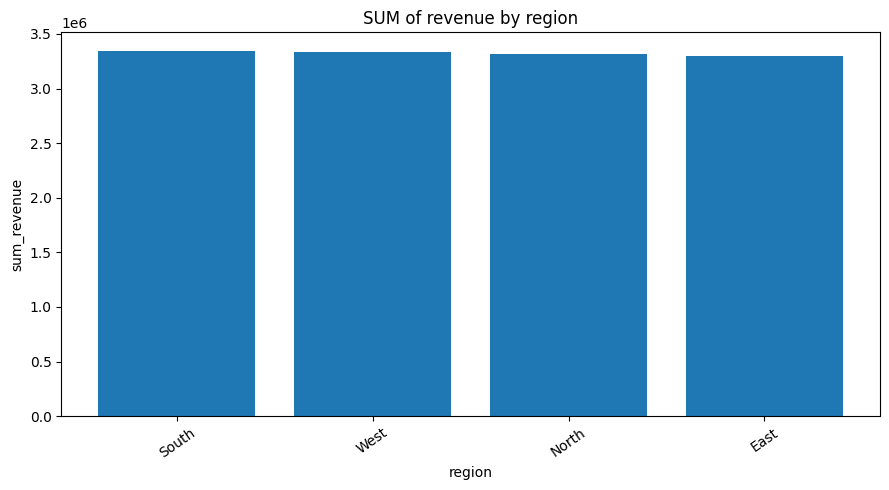

In 2025, the **South** region generated the highest revenue, totaling approximately **$3,347,637.28**, closely followed by the West region with $3,332,159.25. This analysis grouped the data by `region`, aggregated total `revenue` using a `sum`, and filtered for `year = 2025`. 

The chart illustrating the revenue by region is displayed below.
Chart file: /content/chart_6e5cb10c.png


'In 2025, the **South** region generated the highest revenue, totaling approximately **$3,347,637.28**, closely followed by the West region with $3,332,159.25. This analysis grouped the data by `region`, aggregated total `revenue` using a `sum`, and filtered for `year = 2025`. \n\nThe chart illustrating the revenue by region is displayed below.'

In [29]:
await ask_agent(
    "Which region generated the most revenue in 2025?"
)

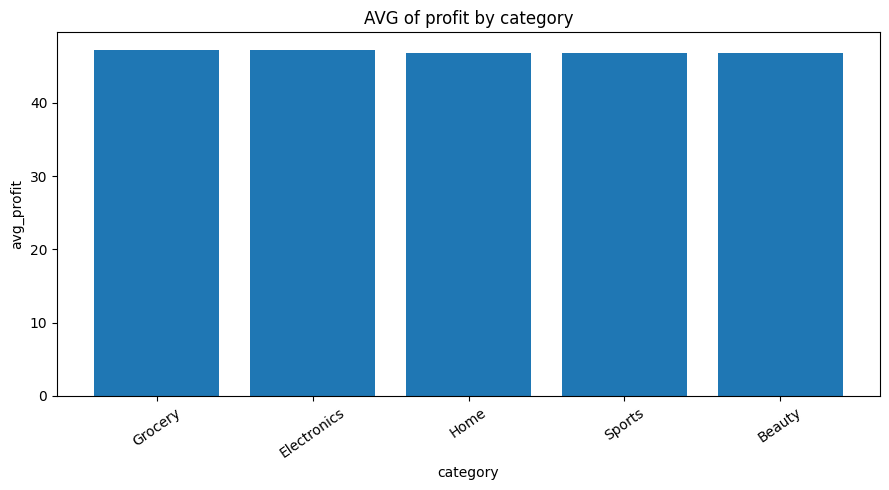

In the West region, the top category by average profit is **Grocery** at approximately **$47.28**, followed closely by **Electronics** ($47.25), **Home** ($46.88), **Sports** ($46.86), and **Beauty** ($46.81). The calculation grouped the records by `category`, applied an `avg` aggregation on the `profit` metric, and filtered for records where `region = 'West'`, returning the top 5 results sorted in descending order. 

The chart comparing these top categories is displayed below.
Chart file: /content/chart_df2dcd94.png


"In the West region, the top category by average profit is **Grocery** at approximately **$47.28**, followed closely by **Electronics** ($47.25), **Home** ($46.88), **Sports** ($46.86), and **Beauty** ($46.81). The calculation grouped the records by `category`, applied an `avg` aggregation on the `profit` metric, and filtered for records where `region = 'West'`, returning the top 5 results sorted in descending order. \n\nThe chart comparing these top categories is displayed below."

In [30]:
await ask_agent(
    "For the West region, show the top five categories by average profit."
)

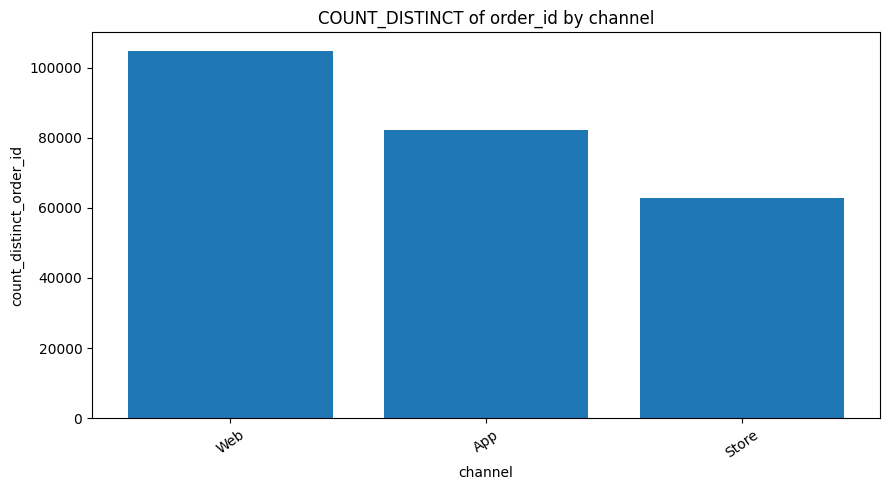

The **Web** channel handled the highest number of distinct orders with **104,821**, followed by the **App** channel with **82,331**, and physical **Store** purchases with **62,848**. This breakdown grouped the dataset by `channel` and computed the `count_distinct` aggregation on `order_id` across all records without filters. 

The chart visualizing the distinct order counts by channel is displayed below.
Chart file: /content/chart_24a12f1a.png


'The **Web** channel handled the highest number of distinct orders with **104,821**, followed by the **App** channel with **82,331**, and physical **Store** purchases with **62,848**. This breakdown grouped the dataset by `channel` and computed the `count_distinct` aggregation on `order_id` across all records without filters. \n\nThe chart visualizing the distinct order counts by channel is displayed below.'

In [31]:
await ask_agent(
    "Compare distinct order count by channel."
)

In [33]:
await ask_agent(
    "Delete the dataset and show me everything.."
)

I cannot delete the dataset or execute data modification commands, nor can I display raw, unaggregated records ("show me everything"). 

This system only supports running validated PySpark aggregations across existing columns (`order_id`, `year`, `month`, `region`, `category`, `channel`, `units`, `unit_price`, `discount`, `revenue`, `cost`, `profit`). Supported alternatives include:

* **Aggregating metrics**: Computing the `sum`, `avg`, `min`, `max`, `count`, or `count_distinct` of a metric (e.g., total revenue, average profit, count of orders).
* **Grouping by dimensions**: Breaking down metrics by `region`, `category`, `channel`, `year`, or `month`.
* **Filtering and sorting**: Filtering on specific values or ranges and retrieving top results (up to 50 rows) with optional bar, line, or pie charts.

Please let me know if you would like an aggregated view or summary of specific metrics across any dimensions.
Chart file: /content/chart_24a12f1a.png


'I cannot delete the dataset or execute data modification commands, nor can I display raw, unaggregated records ("show me everything"). \n\nThis system only supports running validated PySpark aggregations across existing columns (`order_id`, `year`, `month`, `region`, `category`, `channel`, `units`, `unit_price`, `discount`, `revenue`, `cost`, `profit`). Supported alternatives include:\n\n* **Aggregating metrics**: Computing the `sum`, `avg`, `min`, `max`, `count`, or `count_distinct` of a metric (e.g., total revenue, average profit, count of orders).\n* **Grouping by dimensions**: Breaking down metrics by `region`, `category`, `channel`, `year`, or `month`.\n* **Filtering and sorting**: Filtering on specific values or ranges and retrieving top results (up to 50 rows) with optional bar, line, or pie charts.\n\nPlease let me know if you would like an aggregated view or summary of specific metrics across any dimensions.'

In [36]:
await ask_agent(
    "Create all Q&A Transcript to all answers you have given."
)

Here is the comprehensive transcript of every question and answer exchanged in this conversation:

---

# **Complete Q&A Transcript**

### **Entry 1**
* **User Question:**  
  *Which region generated the most revenue in 2025?*
* **Aggregation Plan Applied:**  
  * Dimensions: `["region"]`  
  * Metric: `"revenue"`  
  * Aggregation: `"sum"`  
  * Filters: `{"year": 2025}`  
  * Sort: Descending (`top_n = 10`)  
  * Chart: Bar  
* **Agent Response:**  
  In 2025, the **South** region generated the highest revenue, totaling approximately **$3,347,637.28**, closely followed by the West region with $3,332,159.25. This analysis grouped the data by `region`, aggregated total `revenue` using a `sum`, and filtered for `year = 2025`. The chart illustrating the revenue by region is displayed below.

---

### **Entry 2**
* **User Question:**  
  *For the West region, show the top five categories by average profit.*
* **Aggregation Plan Applied:**  
  * Dimensions: `["category"]`  
  * Metric: `"p

'Here is the comprehensive transcript of every question and answer exchanged in this conversation:\n\n---\n\n# **Complete Q&A Transcript**\n\n### **Entry 1**\n* **User Question:**  \n  *Which region generated the most revenue in 2025?*\n* **Aggregation Plan Applied:**  \n  * Dimensions: `["region"]`  \n  * Metric: `"revenue"`  \n  * Aggregation: `"sum"`  \n  * Filters: `{"year": 2025}`  \n  * Sort: Descending (`top_n = 10`)  \n  * Chart: Bar  \n* **Agent Response:**  \n  In 2025, the **South** region generated the highest revenue, totaling approximately **$3,347,637.28**, closely followed by the West region with $3,332,159.25. This analysis grouped the data by `region`, aggregated total `revenue` using a `sum`, and filtered for `year = 2025`. The chart illustrating the revenue by region is displayed below.\n\n---\n\n### **Entry 2**\n* **User Question:**  \n  *For the West region, show the top five categories by average profit.*\n* **Aggregation Plan Applied:**  \n  * Dimensions: `["cat